# საკრედიტო ბარათების მომხმარებელთა შენარჩუნების AI სისტემა

> მონაცემები: Sakshi Goyal, [Credit Card customers](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers). 10 127 ანონიმური მომხმარებელი.

# ნაწილი 1. პრობლემის განსაზღვრა და მონაცემების ანალიზი

## 1. ბიზნესპრობლემა

ბანკი კარგავს საკრედიტო ბარათების მომხმარებლებს (დაახლოებით 16% წავიდა). ახალი მომხმარებლის მოზიდვა უფრო ძვირია, ვიდრე არსებულის შენარჩუნება, ამიტომ წასვლის რისკის მქონე მომხმარებლები წინასწარ უნდა გამოვლინდეს.

სისტემა:
- პროგნოზირებს, დატოვებს თუ არა მომხმარებელი ბანკს.
- ყოფს მომხმარებლებს ქცევის მიხედვით ჯგუფებად.
- ირჩევს შენარჩუნების მოქმედებას (ფასდაკლება, შეტყობინება ან არაფერი).

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("BankChurners.csv")
print(df.shape)
df.head()

(10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


## 2. მონაცემთა მომზადება

- ცარიელი უჯრები არ არის, მაგრამ `Education_Level`, `Marital_Status` და `Income_Category` სვეტებში გამოტოვებული მნიშვნელობები ჩაწერილია როგორც "Unknown". ვტოვებთ ცალკე კატეგორიად, რადგან წაშლით ბევრ მონაცემს დავკარგავდით (მაგ. 15% `Education_Level`-ში).

In [86]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  str    
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                                      

In [87]:
df.isnull().sum()

CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category                                 

In [88]:
# Missing values hidden as "Unknown" in text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns
(df[text_cols] == "Unknown").sum()

Attrition_Flag        0
Gender                0
Education_Level    1519
Marital_Status      749
Income_Category    1112
Card_Category         0
dtype: int64

- `Naive_Bayes_...` სვეტები სხვა მოდელის პროგნოზებია. მათი დატოვება target leakage იქნებოდა, ამიტომ ვშლით.
- `CLIENTNUM` (ID) და `Avg_Open_To_Buy` (სხვა სვეტებიდან გამოითვლება) ახალ ინფორმაციას არ იძლევა.
- `Attrition_Flag` გადავიყვანეთ რიცხვით სვეტად `Churn` (1 = წავიდა, 0 = დარჩა).
- შედეგად: 13 რიცხვითი და 5 კატეგორიული მახასიათებელი.

In [89]:
# Avg_Open_To_Buy is exactly Credit_Limit - Total_Revolving_Bal
print((df["Credit_Limit"] - df["Total_Revolving_Bal"] - df["Avg_Open_To_Buy"]).abs().max())

leak_cols = [c for c in df.columns if c.startswith("Naive_Bayes")]
df = df.drop(columns=leak_cols + ["CLIENTNUM", "Avg_Open_To_Buy"])

df["Churn"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)
df = df.drop(columns=["Attrition_Flag"])
df.shape

5.684341886080802e-14


(10127, 19)

## 3. სტატისტიკა და ვიზუალიზაცია

- ძირითადი სტატისტიკა (mean, median, std, min, max) რიცხვითი სვეტებისთვის.

In [90]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.0,46.33,8.02,26.0,41.00,46.00,52.00,73.00
Dependent_count,10127.0,2.35,1.30,0.0,1.00,2.00,3.00,5.00
Months_on_book,10127.0,35.93,7.99,13.0,31.00,36.00,40.00,56.00
Total_Relationship_Count,10127.0,3.81,1.55,1.0,3.00,4.00,5.00,6.00
Months_Inactive_12_mon,10127.0,2.34,1.01,0.0,2.00,2.00,3.00,6.00
Contacts_Count_12_mon,10127.0,2.46,1.11,0.0,2.00,2.00,3.00,6.00
Credit_Limit,10127.0,8631.95,9088.78,1438.3,2555.00,4549.00,11067.50,34516.00
Total_Revolving_Bal,10127.0,1162.81,814.99,0.0,359.00,1276.00,1784.00,2517.00
Total_Amt_Chng_Q4_Q1,10127.0,0.76,0.22,0.0,0.63,0.74,0.86,3.40
Total_Trans_Amt,10127.0,4404.09,3397.13,510.0,2155.50,3899.00,4741.00,18484.00


- 16% წავიდა, 84% დარჩა. თუ უბრალოდ ვივარაუდეთ რომ ყველა მომხმარებელი დარჩება (baseline), 84% სიზუსტეს მივიღებთ.

In [91]:
df["Churn"].value_counts(normalize=True)

Churn
0    0.83934
1    0.16066
Name: proportion, dtype: float64

- წასულ მომხმარებლებს გაცილებით ნაკლები ტრანზაქცია აქვთ (მედიანა 43 vs 71) და ნაკლებს ხარჯავენ.

In [92]:
cols = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal",
        "Contacts_Count_12_mon", "Months_Inactive_12_mon"]
df.groupby("Churn")[cols].median().T

Churn,0,1
Total_Trans_Ct,71.0,43.0
Total_Trans_Amt,4100.0,2329.0
Total_Revolving_Bal,1364.0,0.0
Contacts_Count_12_mon,2.0,3.0
Months_Inactive_12_mon,2.0,3.0


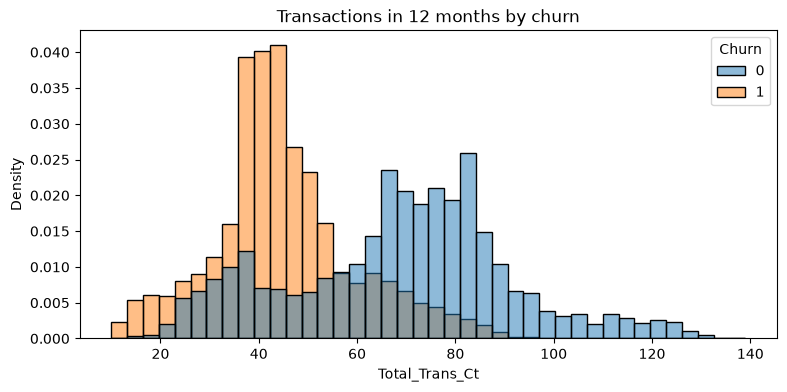

In [93]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="Total_Trans_Ct", hue="Churn", bins=40, stat="density", common_norm=False)
plt.title("Transactions in 12 months by churn")
plt.show()

- რაც მეტჯერ უკავშირდება მომხმარებელი ბანკს, მით მეტია წასვლის ალბათობა (6 კონტაქტისას 100%). 
- უმოქმედო თვეების ზრდასთან ერთად წასვლის წილიც იზრდება (0 თვის ჯგუფში მხოლოდ 29 ადამიანია, ამიტომ ის სანდო არ არის).

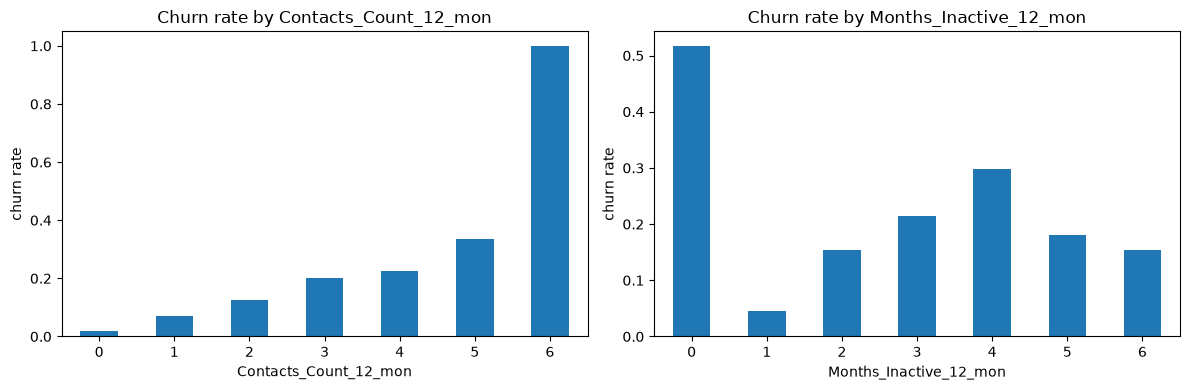

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Contacts_Count_12_mon", "Months_Inactive_12_mon"]):
    df.groupby(col)["Churn"].mean().plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("churn rate")
plt.tight_layout()
plt.show()

## 4. წესებზე დაფუძნებული გადაწყვეტა vs მანქანური სწავლება

წესებზე დაფუძნებულ სისტემაში ლოგიკას ადამიანი წერს, მაგალითად: "თუ კონტაქტები ≥ 4 ან უმოქმედო თვეები ≥ 3, და ტრანზაქციები < 50, მომხმარებელი წავა".

ეს წესი baseline-ზე უარესია. ხელით შეიძლება მხოლოდ რამდენიმე მახასიათებლის გათვალისწინება და ზღვრები ინტუიციით ირჩევა. მანქანური სწავლება წესებსა და ზღვრებს თავად პოულობს მონაცემებიდან, ყველა მახასიათებელს ერთად ითვალისწინებს და ახალ მონაცემებზე თავიდან გაწვრთნით ადაპტირდება. მაგრამ მას სჭირდება მონიშნული მონაცემები, ხოლო ზოგი მოდელი (მაგ. ნეირონული ქსელი) Black box-ია: კარგად არ ჩანს, რატომ მიიღო სისტემამ კონკრეტული გადაწყვეტილება.

In [95]:
rule = (((df["Contacts_Count_12_mon"] >= 4) | (df["Months_Inactive_12_mon"] >= 3))
        & (df["Total_Trans_Ct"] < 50)).astype(int)
print(f"rule accuracy: {(rule == df['Churn']).mean():.1%}")
print(f"baseline:      {(df['Churn'] == 0).mean():.1%}")

rule accuracy: 82.4%
baseline:      83.9%


# ნაწილი 2. Supervised Learning: პროგნოზირება

## 5. Features და Target

- **Target (`y`):** `Churn`, 1 = მომხმარებელი წავიდა, 0 = დარჩა.
- **Features (`X`):** დანარჩენი 18 სვეტი: "Customer_Age","Gender","Dependent_count","Education_Level",
"Marital_Status","Income_Category","Card_Category","Months_on_book","Total_Relationship_Count","Months_Inactive_12_mon",
"Contacts_Count_12_mon","Credit_Limit","Total_Revolving_Bal","Total_Amt_Chng_Q4_Q1","Total_Trans_Amt",
"Total_Trans_Ct","Total_Ct_Chng_Q4_Q1","Avg_Utilization_Ratio".
- კატეგორიული სვეტები one-hot კოდირებით (`get_dummies`) გადავიყვანეთ 0/1 სვეტებად, რადგან მოდელი მხოლოდ რიცხვებთან მუშაობს.

In [96]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True)
y = df["Churn"]
X.shape

(10127, 31)

## 6. სასწავლო და სატესტო ნაწილები

80% სწავლებისთვის, 20% შემოწმებისთვის. `stratify=y` ორივე ნაწილში წასულთა ერთნაირ წილს (16%) ინარჩუნებს.

In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(8101, 31) (2026, 31)


## 7. Decision Tree

ხის სიღრმე შევზღუდეთ (`max_depth=5`), რომ მოდელმა სასწავლო მონაცემები ზეპირად არ დაიმახსოვროს (overfitting) და ხე წაკითხვადი დარჩეს.

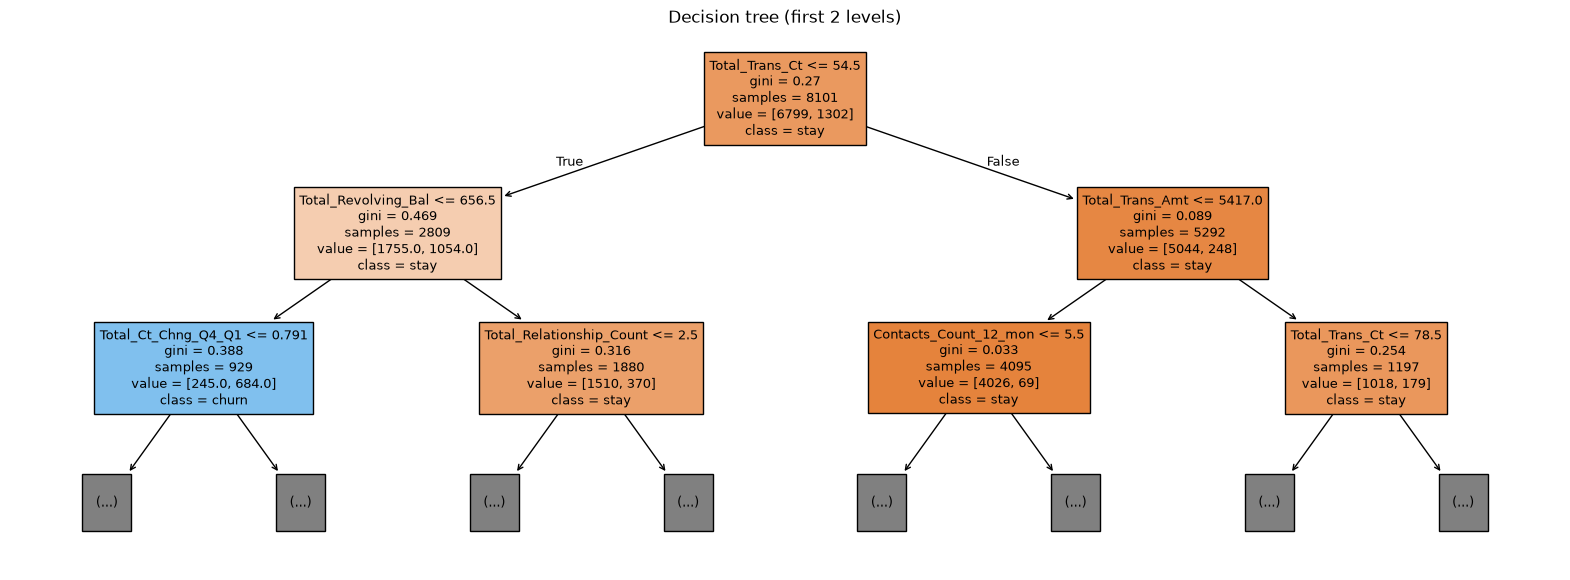

In [98]:
tree = DecisionTreeClassifier(max_depth=5, random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(20, 7))
plot_tree(tree, max_depth=2, feature_names=X.columns, class_names=["stay", "churn"],
          filled=True, fontsize=9)
plt.title("Decision tree (first 2 levels)")
plt.show()

## 8. შეფასება

- სატესტო სიზუსტე **93.1%**, baseline 84.0%. მოდელი 100-დან 9 მომხმარებელს უფრო სწორად აფასებს, ვიდრე "everyone stays".
- სასწავლო (94.7%) და სატესტო სიზუსტე ახლოსაა, ანუ overfitting არ არის.
- დაუბალანსებელ მონაცემებზე მხოლოდ accuracy საკმარისი არ არის: confusion matrix აჩვენებს, რომ 325 წასულიდან მოდელმა 236 (73%) დაიჭირა, 89 გამორჩა.


train accuracy: 94.7%
test accuracy:  93.1%
baseline:       84.0%


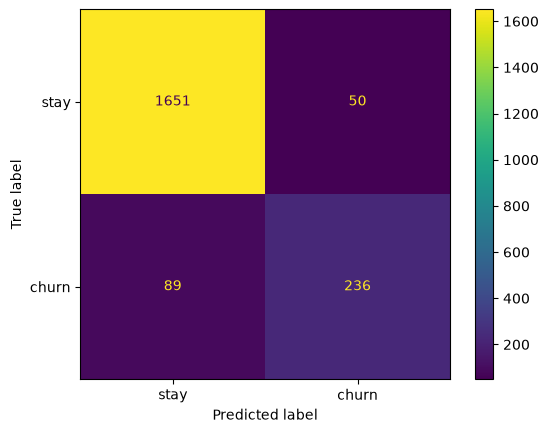

In [99]:
y_pred = tree.predict(X_test)
print(f"train accuracy: {accuracy_score(y_train, tree.predict(X_train)):.1%}")
print(f"test accuracy:  {accuracy_score(y_test, y_pred):.1%}")
print(f"baseline:       {(y_test == 0).mean():.1%}")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["stay", "churn"]).plot()
plt.show()

- ყველაზე მნიშვნელოვანი მახასიათებლებია ტრანზაქციების რაოდენობა, ბრუნვადი ნაშთი და ბანკის პროდუქტების რაოდენობა, რაც პირველ ნაწილში ნანახს ემთხვევა.

In [100]:
pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(5)

Total_Trans_Ct              0.393567
Total_Revolving_Bal         0.257952
Total_Relationship_Count    0.135030
Total_Trans_Amt             0.116536
Total_Ct_Chng_Q4_Q1         0.068093
dtype: float64

## 9. რატომ არის ეს Supervised Learning

თითოეულ მაგალითს აქვს ცნობილი სწორი პასუხი (label): ვიცით, წავიდა თუ არა მომხმარებელი. მოდელი სწავლობს features-დან ამ პასუხის პროგნოზს და შემდეგ ახალ მომხმარებლებზე იყენებს. რადგან target კატეგორიულია (წავა / არ წავა), ეს კლასიფიკაციის ამოცანაა.

# ნაწილი 3. Unsupervised Learning: დაჯგუფება

## 10. მახასიათებლების შერჩევა და სკალირება

დაჯგუფებისთვის ავირჩიეთ ბარათის გამოყენების ქცევის 4 მახასიათებელი: `Total_Trans_Amt` (ხარჯი), `Total_Trans_Ct` (ტრანზაქციების რაოდენობა), `Credit_Limit` (ლიმიტი) და `Avg_Utilization_Ratio` (ლიმიტის რა წილს იყენებს). `Churn` არ გამოგვიყენებია, რადგან unsupervised სწავლებას პასუხი არ სჭირდება.

K-Means მანძილებით მუშაობს, ხოლო სვეტების მასშტაბი ძალიან განსხვავდება (ლიმიტი ათასობით, utilization 0-დან 1-მდე). სკალირების გარეშე ლიმიტი გადაწყვეტდა ყველაფერს, ამიტომ `StandardScaler`-ით ყველა სვეტი ერთ მასშტაბზე (საშუალო 0, სტანდარტული გადახრა 1) გადავიყვანეთ.

In [101]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_cols = ["Total_Trans_Amt", "Total_Trans_Ct", "Credit_Limit", "Avg_Utilization_Ratio"]
X_scaled = StandardScaler().fit_transform(df[cluster_cols])

## 11. K-Means, 3 კლასტერი

In [102]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)
df["Cluster"].value_counts().sort_index()

Cluster
0    5345
1    1183
2    3599
Name: count, dtype: int64

## 12. კლასტერების ვიზუალიზაცია და აღწერა

სამი ჯგუფი მკაფიოდ განსხვავდება:
- **აქტიური მომხმარებლები** (~1 200): ბევრს ხარჯავენ (საშუალოდ ~12 300) და ბევრ ტრანზაქციას აკეთებენ (~100), მაღალი ლიმიტი აქვთ. წასვლის წილი 8%.
- **კრედიტზე დამოკიდებული** (~3 600): დაბალი ლიმიტი (~2 800), მაგრამ მის 60%-ს იყენებენ. წასვლის წილი 9%.
- **პასიური მომხმარებლები** (~5 300): მაღალი ლიმიტი აქვთ, მაგრამ თითქმის არ იყენებენ (utilization 8%) და ცოტას ხარჯავენ. წასვლის წილი **23%**, ყველაზე მაღალი.

`Churn` დაჯგუფებაში არ მონაწილეობდა, მაგრამ კლასტერები მაინც გამოყოფს რისკის ჯგუფს: შენარჩუნების კამპანია პირველ რიგში პასიურ მომხმარებლებზე უნდა იყოს მიმართული.

In [103]:
profile = df.groupby("Cluster")[cluster_cols + ["Churn"]].mean().round(2)
profile["Size"] = df["Cluster"].value_counts().sort_index()
profile

,Total_Trans_Amt,Total_Trans_Ct,Credit_Limit,Avg_Utilization_Ratio,Churn,Size
Cluster,,,,,,
0,3137.07,56.76,10889.07,0.08,0.23,5345
1,12301.70,102.42,16038.74,0.15,0.08,1183
2,3689.81,64.54,2845.21,0.60,0.09,3599


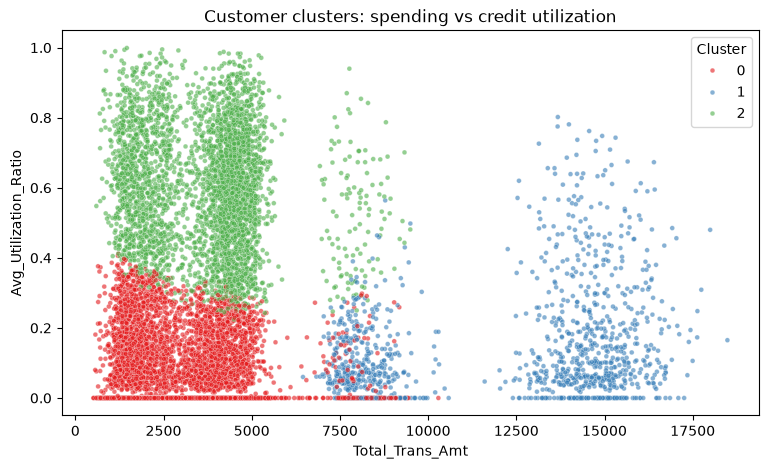

In [104]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="Total_Trans_Amt", y="Avg_Utilization_Ratio",
                hue="Cluster", palette="Set1", s=12, alpha=0.6)
plt.title("Customer clusters: spending vs credit utilization")
plt.show()

## 13. Supervised vs Unsupervised Learning

- **Supervised:** მონაცემებს აქვს სწორი პასუხი (`Churn`). მოდელი სწავლობს მის პროგნოზს და სიზუსტით ფასდება.
- **Unsupervised:** პასუხი არ გვაქვს. ალგორითმი თავად პოულობს მონაცემებში მსგავსი ობიექტების ჯგუფებს. "სწორი" შედეგი არ არსებობს, კლასტერების მნიშვნელობას ადამიანი განმარტავს.

Supervised პასუხობს კითხვას "წავა თუ არა ეს მომხმარებელი?", unsupervised კი "რა ტიპის მომხმარებლები გვყავს?".

# ნაწილი 4. Reinforcement Learning: გადაწყვეტილების მიღება

## 14. Agent, Environment, Action, Reward

- **Agent:** ბანკის შენარჩუნების სისტემა, რომელიც წყვეტს, რა გააკეთოს თითოეულ მომხმარებელთან.
- **Environment:** მომხმარებლები და მათი რეაქცია. მდგომარეობა (state) არის მომხმარებლის სეგმენტი მე-3 ნაწილიდან: აქტიური, კრედიტზე დამოკიდებული ან პასიური.
- **Action:** A - ფასდაკლება, B - პერსონალიზებული შეტყობინება, C - გამოტოვება.
- **Reward:** +20, თუ მომხმარებელი დარჩა, მინუს მოქმედების ღირებულება (A = 4, B = 1, C = 0). ფასდაკლება ყველაზე ეფექტურია, მაგრამ ყველაზე ძვირიც.

## 15. სიმულაციური გარემო

თითოეული სეგმენტისთვის და მოქმედებისთვის განვსაზღვრეთ მომხმარებლის დარჩენის ალბათობა (გამოგონილი, მაგრამ ლოგიკური მნიშვნელობები). აგენტმა ეს ალბათობები არ იცის, მან მხოლოდ ჯილდოებიდან უნდა ისწავლოს.

In [105]:
import numpy as np

rng = np.random.default_rng(42)

STATES = ["Active", "Credit-dependent", "Passive"]
ACTIONS = ["A: discount", "B: message", "C: skip"]
COST = np.array([4, 1, 0])
RETAIN_REWARD = 20

# Probability the customer stays, rows = states, columns = actions (hidden from the agent)
STAY_PROB = np.array([
    [0.90, 0.90, 0.95],  # Active: loyal already, offers barely matter
    [0.98, 0.70, 0.60],  # Credit-dependent: price sensitive, discount works best
    [0.80, 0.95, 0.65],  # Passive: a personal reminder brings them back
])


class RetentionEnv:
    """One step = one customer contact. reset() draws a random segment, step(action) returns the reward."""

    def reset(self) -> int:
        self.state = int(rng.integers(len(STATES)))
        return self.state

    def step(self, action: int) -> float:
        stays = rng.random() < STAY_PROB[self.state, action]
        return RETAIN_REWARD * stays - COST[action]

## 16. Q-Learning

Q-ცხრილი ინახავს შეფასებას `Q(s, a)`: რამდენ ჯილდოს მოიტანს მოქმედება `a` მდგომარეობაში `s`. ყოველი ნაბიჯის შემდეგ ის ახლდება:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \, (r - Q(s,a))$$

- $\alpha = 0.02$: სწავლის სიჩქარე, რამდენად გადაიწევს Q ახალი ჯილდოსკენ;
- $\varepsilon = 0.2$: შემთხვევების 20%-ში აგენტი შემთხვევით მოქმედებას ცდის (exploration), დანარჩენში საუკეთესოს ირჩევს (exploitation).

ქვემოთ ჩანს პირველი 5 ნაბიჯის განახლება და საბოლოო Q-ცხრილი 20 000 ნაბიჯის შემდეგ.

აგენტმა ისწავლა: აქტიურ მომხმარებელს არაფერი შესთავაზო (ისედაც რჩება, ხარჯი ზედმეტია), კრედიტზე დამოკიდებულს ფასდაკლება, პასიურს პერსონალიზებული შეტყობინება. Q-მნიშვნელობები ჭეშმარიტ საშუალო ჯილდოსთან ახლოსაა, თუმცა აგენტს ეს ალბათობები არასდროს უნახავს.


In [106]:
alpha, epsilon, steps = 0.02, 0.2, 20_000
Q = np.zeros((len(STATES), len(ACTIONS)))
env = RetentionEnv()

for t in range(steps):
    s = env.reset()
    a = int(rng.integers(len(ACTIONS))) if rng.random() < epsilon else int(Q[s].argmax())
    r = env.step(a)
    old = Q[s, a]
    Q[s, a] += alpha * (r - Q[s, a])
    if t < 5:
        print(f"step {t + 1}: {STATES[s]:<16} {ACTIONS[a]:<12} reward={r:>3}  Q: {old:.2f} -> {Q[s, a]:.2f}")

step 1: Active           A: discount  reward= 16  Q: 0.00 -> 0.32
step 2: Passive          A: discount  reward= 16  Q: 0.00 -> 0.32
step 3: Credit-dependent A: discount  reward= 16  Q: 0.00 -> 0.32
step 4: Passive          C: skip      reward= 20  Q: 0.00 -> 0.40
step 5: Credit-dependent A: discount  reward= 16  Q: 0.32 -> 0.63


In [107]:
expected = RETAIN_REWARD * STAY_PROB - COST  # true average reward, for comparison only
pd.concat({"learned Q": pd.DataFrame(Q, STATES, ACTIONS).round(1),
           "true expected reward": pd.DataFrame(expected, STATES, ACTIONS)}, axis=1)

learned Q                    true expected reward  \
                 A: discount B: message C: skip          A: discount   
Active                  13.8       16.9    18.5                 14.0   
Credit-dependent        15.4       13.7    13.0                 15.6   
Passive                 12.0       17.7    13.2                 12.0   

                                     
                 B: message C: skip  
Active                 17.0    19.0  
Credit-dependent       13.0    12.0  
Passive                18.0    13.0

In [108]:
for s, name in enumerate(STATES):
    print(f"{name:<16} -> {ACTIONS[Q[s].argmax()]}")

Active           -> C: skip
Credit-dependent -> A: discount
Passive          -> B: message


## 17. როგორ სწავლობს აგენტი

აგენტი სწავლობს ცდითა და შეცდომით: ცდის მოქმედებას, იღებს ჯილდოს და Q-მნიშვნელობას ამ ჯილდოსკენ ოდნავ გადაწევს. დროთა განმავლობაში Q ყველა მოქმედების საშუალო ჯილდოს უახლოვდება და აგენტი უფრო ხშირად ირჩევს საუკეთესოს. ε-ს გამო მაინც ცდის სხვა მოქმედებებსაც, რომ უკეთესი ვარიანტი არ გამორჩეს.

**განსხვავება Supervised Learning-ისგან:** supervised-ში ყოველ მაგალითს აქვს სწორი პასუხი. აქ სწორ პასუხს არავინ ეუბნება აგენტს, ის მხოლოდ თავისი მოქმედების შედეგს (ჯილდოს) იღებს და თავად უნდა აღმოაჩინოს, რომელი მოქმედებაა საუკეთესო. მონაცემებსაც თავად აგროვებს თავისი მოქმედებებით.

# ნაწილი 5. ნეირონული ქსელები

## 18. Feedforward Neural Network

ვიყენებთ `MLPClassifier`-ს იმავე train/test მონაცემებზე, რაც მე-2 ნაწილში. ნეირონული ქსელი სკალირებას საჭიროებს, ამიტომ `StandardScaler` და მოდელი ერთ `pipeline`-შია: სკალერი მხოლოდ სასწავლო მონაცემებზე სწავლობს. `early_stopping=True` წყვეტს სწავლებას, როცა ვალიდაციის შედეგი აღარ უმჯობესდება, რაც overfitting-ს ამცირებს.

In [109]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import recall_score

mlp_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu",
                  early_stopping=True, max_iter=500, random_state=42),
)
mlp_model.fit(X_train, y_train)
mlp = mlp_model[-1]
print("layers:", [X_train.shape[1], *mlp.hidden_layer_sizes, 1])
print("output activation:", mlp.out_activation_, "| epochs:", mlp.n_iter_)

layers: [31, 16, 8, 1]
output activation: logistic | epochs: 58


## 19. ფენები და აქტივაციის ფუნქცია

- **შემავალი ფენა:** 31 ნეირონი, თითო თითოეული მახასიათებლისთვის (one-hot კოდირების შემდეგ).
- **დამალული ფენები:** 16 და 8 ნეირონი. თითოეული ნეირონი წინა ფენის მნიშვნელობების შეწონილ ჯამს ითვლის და აქტივაციის ფუნქციას ატარებს. ასე ქსელი რთულ, არაწრფივ კავშირებს სწავლობს.
- **აქტივაცია: ReLU**, $f(x) = \max(0, x)$. მარტივი და სწრაფია. მის გარეშე ქსელი წრფივი მოდელი იქნებოდა, რამდენი ფენაც არ უნდა ჰქონდეს.
- **გამომავალი ფენა:** 1 ნეირონი sigmoid (logistic) ფუნქციით, რომელიც წასვლის ალბათობას (0-დან 1-მდე) იძლევა.

## 20. Backpropagation

სწავლება ციკლურად მიმდინარეობს:
1. **Forward pass:** მონაცემები ფენებს გადის და ქსელი პროგნოზს აკეთებს.
2. **Loss:** ითვლება, რამდენად შორსაა პროგნოზი სწორი პასუხისგან.
3. **Backpropagation:** შეცდომა უკან, გამომავალი ფენიდან შემავლისკენ ვრცელდება და ითვლება, რამდენად შეუწყო ხელი თითოეულმა წონამ შეცდომას (გრადიენტი).
4. **წონების განახლება:** ოპტიმიზატორი (Adam) წონებს გრადიენტის საწინააღმდეგო მიმართულებით ოდნავ ცვლის, რომ შეცდომა შემცირდეს.

ქვემოთ ჩანს, როგორ მცირდება loss ყოველ ეპოქაზე.

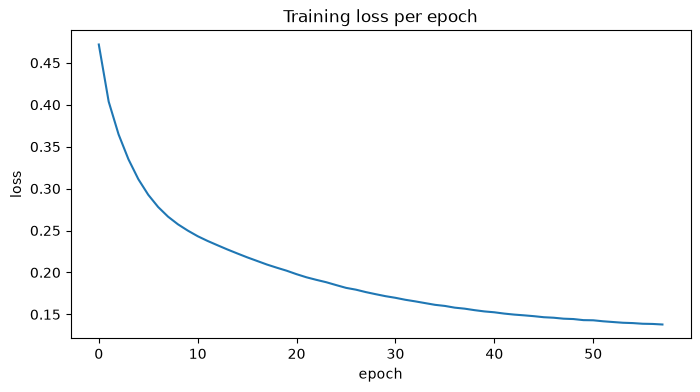

In [110]:
plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_)
plt.title("Training loss per epoch")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

## 21. შედარება Decision Tree-სთან

ნეირონულმა ქსელმა Decision Tree-ს **ვერ აჯობა**: სიზუსტე 92.8% vs 93.1%, წასულთა დაჭერა 71% vs 73%. ცხრილურ მონაცემებზე, სადაც მკაფიო ზღვრებია (მაგ. ტრანზაქციების რაოდენობა), ხე კარგად მუშაობს. ამასთან ხე ახსნადია (დავხატეთ), ქსელი კი black box-ია. ამ ამოცანისთვის Decision Tree უკეთესი არჩევანია.

In [111]:
mlp_pred = mlp_model.predict(X_test)
pd.DataFrame({
    "accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, mlp_pred)],
    "churn recall": [recall_score(y_test, y_pred), recall_score(y_test, mlp_pred)],
}, index=["Decision Tree", "Neural Network"]).round(3)

,accuracy,churn recall
Decision Tree,0.931,0.726
Neural Network,0.928,0.708


# ნაწილი 6. შედარება და დასკვნა

## 22. Supervised, Unsupervised და Reinforcement Learning

| | Supervised | Unsupervised | Reinforcement |
|---|---|---|---|
| **მიზანი** | ცნობილი პასუხის პროგნოზი | ფარული სტრუქტურის (ჯგუფების) პოვნა | საუკეთესო მოქმედების სწავლა |
| **მონაცემები** | მონიშნული მაგალითები (features + label) | მხოლოდ features, label-ის გარეშე | მონაცემები არ აქვს წინასწარ, აგროვებს გარემოსთან ურთიერთობით |
| **შედეგი** | მოდელი, რომელიც ახალ მაგალითს აფასებს | კლასტერები, რომლებსაც ადამიანი განმარტავს | სტრატეგია (policy): რა გააკეთოს თითოეულ მდგომარეობაში |
| **ჩვენს პროექტში** | წავა თუ არა მომხმარებელი (93.1%) | 3 სეგმენტი, მათ შორის პასიური ჯგუფი (23% წასვლა) | რომელ სეგმენტს რა შევთავაზოთ |

## 23. რომელ ამოცანას რომელი მეთოდი

- **Supervised:** როცა ისტორიული მონაცემები სწორი პასუხით გვაქვს და ახალი შემთხვევის შეფასება გვინდა: წასვლის პროგნოზი, თაღლითობის აღმოჩენა, სესხის რისკი.
- **Unsupervised:** როცა პასუხი არ ვიცით და მონაცემების სტრუქტურის გაგება გვინდა: მომხმარებელთა სეგმენტაცია, უჩვეულო ტრანზაქციების პოვნა.
- **Reinforcement:** როცა თანმიმდევრული გადაწყვეტილებები უნდა მივიღოთ და შედეგი მხოლოდ მოქმედების შემდეგ ჩანს: შეთავაზებების შერჩევა, რეკომენდაციები, თამაშები, რობოტიკა.

ერთ სისტემაში ისინი ერთმანეთს ავსებენ: supervised პოულობს რისკის მქონე მომხმარებელს, unsupervised განსაზღვრავს მის სეგმენტს, RL ირჩევს მოქმედებას.

## 24. ნეირონული ქსელის უპირატესობები და შეზღუდვები

**უპირატესობები:**
- სწავლობს რთულ, არაწრფივ კავშირებს მახასიათებლებს შორის;
- კარგად მუშაობს დიდ და არასტრუქტურირებულ მონაცემებზე (სურათები, ტექსტი, ხმა);
- მახასიათებლების ხელით შექმნა ნაკლებად სჭირდება.

**შეზღუდვები:**
- Black box: რთულია ახსნა, რატომ მიიღო კონკრეტული გადაწყვეტილება, რაც ბანკისთვის მნიშვნელოვანია;
- სჭირდება ბევრი მონაცემი, სკალირება და პარამეტრების შერჩევა;
- ადვილად ხდება overfitting, ამიტომ early stopping დაგვჭირდა;
- ჩვენს ცხრილურ მონაცემებზე უფრო მარტივ Decision Tree-ს ვერ აჯობა.

## 25. დაკვირვებები და ეთიკური რისკები

### დაკვირვებები
1. **აქტივობა წასვლის მთავარი ნიშანია.** ტრანზაქციების რაოდენობა ყველაზე მნიშვნელოვანი მახასიათებელია როგორც მედიანების შედარებით (43 vs 71), ისე ხის მიხედვით. წასვლამდე მომხმარებელი ბარათს ნაკლებად იყენებს, ამიტომ აქტივობის კლება ადრეული გაფრთხილებაა.
2. **Accuracy მარტო შეცდომაში შემყვანია.** baseline (everyone stays) 84%-ს იძლევა. ჩვენი მოდელი 93%-ს აღწევს, მაგრამ წასულთა 27% მაინც გამორჩება. ბანკისთვის სწორედ ეს მომხმარებლებია მნიშვნელოვანი.
3. **მარტივი მოდელი საკმარისია.** Decision Tree-მ ნეირონულ ქსელს აჯობა და თან ახსნადია.
4. **Unsupervised სწავლებამ label-ის გარეშე იპოვა რისკის ჯგუფი:** პასიური მომხმარებლები (მაღალი ლიმიტი, დაბალი გამოყენება) 23%-ით ტოვებენ ბანკს, დანარჩენები 8-9%-ით.

### ეთიკური რისკები
- **მიკერძოება:** მონაცემებში არის სქესი, შემოსავალი, განათლება და ოჯახური მდგომარეობა. თუ მოდელი მათ გამოიყენებს, შეთავაზებები ზოგ ჯგუფს უსამართლოდ მიაკლდება. ქვემოთ ვამოწმებთ: ჩვენი ხე ამ მახასიათებლებს საერთოდ არ იყენებს და სიზუსტე ქალებსა და კაცებზე თითქმის თანაბარია. თუმცა მათი წაშლა სრულ გარანტიას არ იძლევა, რადგან სხვა სვეტები (მაგ. საკრედიტო ლიმიტი) შეიძლება შემოსავალთან იყოს დაკავშირებული და მის მაგივრად იმუშაოს.
- **კონფიდენციალურობა:** ფინანსური ქცევის მონაცემები მგრძნობიარეა. საჭიროა ანონიმიზაცია (ჩვენს მონაცემებში მხოლოდ რიცხვითი ID-ია), მხოლოდ საჭირო მონაცემების შენახვა და მომხმარებლის თანხმობა.
- **გამჭვირვალობა და ქცევის მანიპულაცია:** თუ ფასდაკლებას მხოლოდ "წასვლის რისკის მქონე" მომხმარებლები იღებენ, ლოიალური მომხმარებლები ფაქტობრივად მეტს იხდიან.

In [112]:
demo_cols = [c for c in X.columns if c.startswith(("Gender", "Income", "Education", "Marital"))]
print("tree importance of demographic features:", tree.feature_importances_[X.columns.get_indexer(demo_cols)].sum())

gender = X_test["Gender_M"].map({True: "M", False: "F"})
pred = pd.Series(y_pred, index=y_test.index)
churned = y_test == 1
pd.DataFrame({
    "customers": gender.value_counts(),
    "accuracy": (pred == y_test).groupby(gender).mean(),
    "churn recall": (pred[churned] == 1).groupby(gender[churned]).mean(),
}).round(3)

tree importance of demographic features: 0.0


,customers,accuracy,churn recall
Gender_M,,,
F,1086,0.933,0.729
M,940,0.930,0.722


## დასკვნა

- გამოვიყენეთ Supervised Learning, Unsupervised Learning, RL და ნეირონული ქსელები და შევქმენით სისტემა, რომელიც churn-ს 93% სიზუსტით პროგნოზირებს.
- Decision Tree-მ საუკეთესო შედეგს მიაღწია.
- K-Means-მა label-ის გარეშე იპოვა რისკის ჯგუფი: პასიური მომხმარებლები (23% წასვლა).
- ნეირონულმა ქსელმა Decision Tree-ს ვერ აჯობა (92.8% vs 93.1%).
- RL აგენტმა სიმულაციაში ისწავლა, რომელ სეგმენტს რომელი შენარჩუნების მოქმედება შეესაბამება. 
- შეზღუდვები: მონაცემებში არ არის კმაყოფილების მაჩვენებელი, ხოლო RL სიმულაციის ალბათობები გამოგონილია და რეალურ ექსპერიმენტს საჭიროებს.

> მონაცემთა წყარო: Sakshi Goyal, [Credit Card customers](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers) (პირველწყარო: analyttica.com)